In [50]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_percentage_error


[*********************100%***********************]  1 of 1 completed


Price                   Close      High       Low      Open  Volume
Datetime                                                           
2026-10-15 02:00:00  29789.25  29942.75  29765.50  29877.75   77648
2026-10-15 03:00:00  29838.50  30182.75  29753.50  29789.75   65372
2026-10-15 04:00:00  29781.50  29846.00  29768.75  29838.50   19988
(11484, 5)


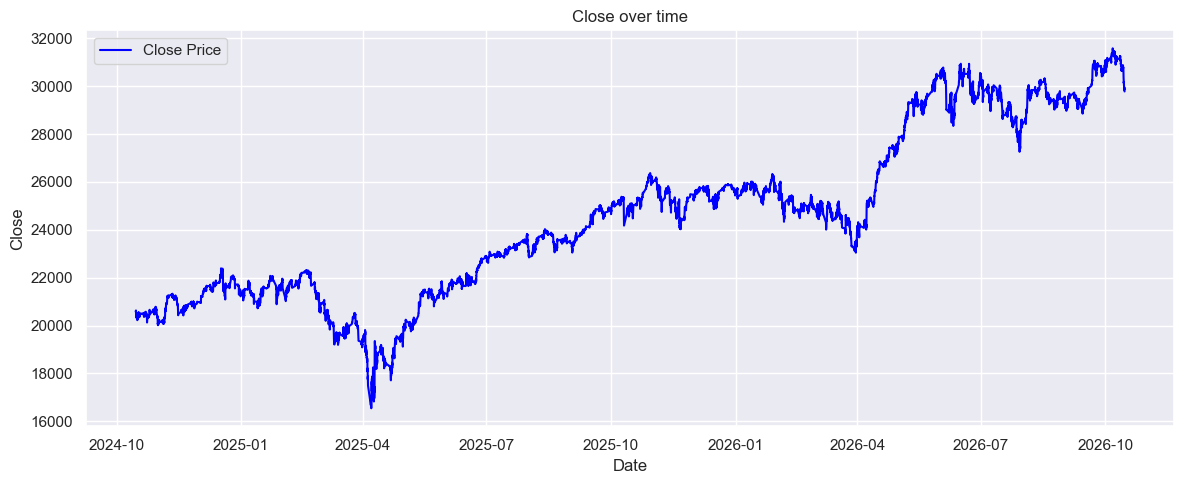

In [51]:
mnq_hr = yf.download("MNQ=F", period='max', interval='1h')
mnq_hr.index = mnq_hr.index.tz_localize(None)
mnq_hr.columns = mnq_hr.columns.droplevel(1)
print(mnq_hr.tail(3))
print(mnq_hr.shape)
sns.set_theme(style="darkgrid")
fig, ax = plt.subplots(figsize=(12,5))
sns.lineplot(data=mnq_hr, x='Datetime', y="Close", label='Close Price', color='blue')
plt.title('Close over time')
plt.xlabel("Date")
plt.ylabel("Close")
plt.tight_layout()
plt.show()

In [52]:
import numpy as np
import pandas as pd
import pandas_ta as ta


def ml_features_mnq(mnq_hr, target_col='Close', lags=12):
  df_ml = mnq_hr.copy()
  df_ml['Hour'] = df_ml.index.hour

  
  df_ml['return_1'] = df_ml[target_col].pct_change(1)
  df_ml['return_3'] = df_ml[target_col].pct_change(3)
  df_ml['return_6'] = df_ml[target_col].pct_change(6)
  df_ml['return_12'] = df_ml[target_col].pct_change(12)
  df_ml['return_24'] = df_ml[target_col].pct_change(24)

  df_ml['SMA_10'] = ta.sma(df_ml[target_col], length=10)
  df_ml['SMA_20'] = ta.sma(df_ml[target_col], length=20)
  df_ml['SMA_50'] = ta.sma(df_ml[target_col], length=50)

  df_ml['EMA_10'] = ta.ema(df_ml[target_col], length=10)
  df_ml['EMA_20'] = ta.ema(df_ml[target_col], length=20)
  df_ml['EMA_50'] = ta.ema(df_ml[target_col], length=50)
  df_ml['EWMA_20'] = df_ml[target_col].ewm(span=20, adjust=False).mean()
  df_ml['EWMA_50'] = df_ml[target_col].ewm(span=50, adjust=False).mean()

  df_ml['close_SMA20'] = df_ml[target_col] / df_ml['SMA_20'] - 1
  df_ml['close_SMA50'] = df_ml[target_col] / df_ml['SMA_50'] - 1
  df_ml['close_EMA20'] = df_ml[target_col] / df_ml['EMA_20'] - 1
  df_ml['close_EMA50'] = df_ml[target_col] / df_ml['EMA_50'] - 1
  df_ml['close_EWMA20'] = df_ml[target_col] / df_ml['EWMA_20'] - 1
  df_ml['close_EWMA50'] = df_ml[target_col] / df_ml['EWMA_50'] - 1

  df_ml['RSI_7'] = ta.rsi(df_ml[target_col], length=7)
  df_ml['RSI_14'] = ta.rsi(df_ml[target_col], length=14)
  df_ml['RSI_28'] = ta.rsi(df_ml[target_col], length=28)

  
  df_ml['ATR'] = ta.atr(df_ml['High'], df_ml['Low'], df_ml['Close'], length=14)
  df_ml['volatility_regime'] = (
      df_ml['ATR'] > df_ml['ATR'].rolling(50).mean()
  ).astype(int)

  macd = ta.macd(df_ml[target_col])
  df_ml['MACD'] = macd['MACD_12_26_9']
  df_ml['MACD_signal'] = macd['MACDs_12_26_9']
  df_ml['MACD_hist'] = macd['MACDh_12_26_9']

  df_ml['volatility_6'] = df_ml['return_1'].rolling(6).std()
  df_ml['volatility_12'] = df_ml['return_1'].rolling(12).std()
  df_ml['volatility_24'] = df_ml['return_1'].rolling(24).std()

  df_ml['range'] = (df_ml['High'] - df_ml['Low']) / df_ml[target_col]
  df_ml['open_close'] = (df_ml['Close'] - df_ml['Open']) / df_ml['Open']
  df_ml['volume_change'] = df_ml['Volume'].pct_change()
  df_ml['volume_sma20'] = df_ml['Volume'].rolling(20).mean()
  df_ml['relative_volume'] = df_ml['Volume'] / df_ml['volume_sma20']

  
  lag_columns = [
      'return_1',
      'return_3',
      'RSI_14',
      'MACD_hist',
      'volatility_12',
      'relative_volume',
  ]
  lag_features = {}
  for col in lag_columns:
    for lag in range(1, lags + 1):
      lag_features[f'{col}_lag{lag}'] = df_ml[col].shift(lag)

  lag_df = pd.DataFrame(lag_features, index=df_ml.index)
  df_ml = pd.concat([df_ml, lag_df], axis=1)


  for h in range(1, 7):
    future_price = df_ml[target_col].shift(-h)
    df_ml[f'Target_H{h}'] = np.where(
        future_price.isna(),
        np.nan,
        (future_price > df_ml[target_col]).astype(int),
    )

  df_ml = df_ml.dropna()
  return df_ml

In [53]:
import numpy as np
import pandas as pd
from sklearn.model_selection._split import _BaseKFold

class PurgedKFold(_BaseKFold):
    """
    Purged K-Fold Cross-Validation for Financial Machine Learning.
    
    Parameters:
    -----------
    n_splits : int
        Number of folds.
    t1 : pd.Series
        A pandas Series where the index is the event start time and 
        the value is the barrier touch / label end time (t1).
    embargo_pct : float
        Percentage of data to embargo after the test set (removes subsequent autocorrelation).
    """
    def __init__(self, n_splits=5, t1=None, embargo_pct=0.01):
        super(PurgedKFold, self).__init__(n_splits, shuffle=False, random_state=None)
        self.t1 = t1
        self.embargo_pct = embargo_pct

    def split(self, X, y=None, groups=None):
        if not isinstance(X.index, pd.DatetimeIndex):
            raise ValueError("X index must be a pandas DatetimeIndex.")
            
        indices = np.arange(X.shape[0])
        n_samples = X.shape[0]
        
        # Define fold boundaries
        test_starts = [(i * n_samples) // self.n_splits for i in range(self.n_splits)]
        test_ends = [((i + 1) * n_samples) // self.n_splits for i in range(self.n_splits)]
        
        for i in range(self.n_splits):
            t0, t1_idx = test_starts[i], test_ends[i]
            test_indices = indices[t0:t1_idx]
            
            test_start_time = X.index[t0]
            test_end_time = X.index[t1_idx - 1] if t1_idx < n_samples else X.index[-1]
            
            # Calculate embargo timestamp (dropping samples immediately following test set)
            embargo_idx = int(n_samples * self.embargo_pct)
            if i < self.n_splits - 1:
                embargo_time = X.index[min(t1_idx + embargo_idx, n_samples - 1)]
            else:
                embargo_time = X.index[-1]
                
            train_indices = []
            for idx in indices:
                sample_time = X.index[idx]
                
                # 1. Embargo check: drop samples immediately after test set
                if test_start_time <= sample_time <= embargo_time:
                    continue
                    
                # 2. Purge check: drop samples whose label overlaps with test set
                if self.t1 is not None and sample_time in self.t1.index:
                    event_end = self.t1.loc[sample_time]
                    # If event ends after test set starts AND sample starts before test set ends -> overlap
                    if not (event_end < test_start_time or sample_time > test_end_time):
                        continue
                else:
                    # Fallback time check if t1 is missing
                    if not (sample_time < test_start_time or sample_time > test_end_time):
                        continue
                        
                train_indices.append(idx)
                
            yield np.array(train_indices), test_indices

In [54]:
def compute_sample_weights(t1_series, price_index):
    """
    Computes concurrency counts and average uniqueness weights for each sample
    based on its lifespan between start time and barrier exit time (t1).
    """
    concurrency = pd.Series(0, index=price_index)
    
    for start_t, end_t in t1_series.items():
        concurrency.loc[start_t:end_t] += 1
        
    weights = []

    for start_t, end_t in t1_series.items():
        u_t = 1.0 / concurrency.loc[start_t:end_t]
        weights.append(u_t.mean())
        
    return np.array(weights)

In [55]:
def get_triple_barrier_labels(df, close_col='Close', high_col='High', low_col='Low', 
                              atr_col='ATR', mult=1.5, max_bars=6):
    """
    Applies the Triple Barrier Method to financial time series data.
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame containing price and ATR columns.
    mult : float
        Multiplier for the ATR to set take-profit and stop-loss widths.
    max_bars : int
        Vertical time barrier limit (max holding period in hours).
        
    Returns:
    --------
    labels : pd.Series
        Binary or ternary classification labels (1 for profit, -1 for loss, 0 for time exit).
    t1 : pd.Series
        Timestamps when each event actually terminated (hit a barrier).
    """
    close = df[close_col]
    high = df[high_col]
    low = df[low_col]
    atr = df[atr_col]
    
    labels = pd.Series(index=df.index, dtype=float)
    t1 = pd.Series(index=df.index, dtype='datetime64[ns]')
    
    prices = close.values
    highs = high.values
    lows = low.values
    atrs = atr.values
    times = df.index
    n = len(df)
    
    for i in range(n - max_bars):
        entry_price = prices[i]
        current_atr = atrs[i]
        
        if np.isnan(current_atr) or current_atr <= 0:
            continue
            
        upper_barrier = entry_price + (mult * current_atr)
        lower_barrier = entry_price - (mult * current_atr)
        
        end_idx = min(i + max_bars, n - 1)
        hit = 0 # 0 = time expired, 1 = profit, -1 = stop loss
        termination_time = times[end_idx]
        
        for j in range(i + 1, end_idx + 1):
            if highs[j] >= upper_barrier:
                hit = 1
                termination_time = times[j]
                break
            
            if lows[j] <= lower_barrier:
                hit = -1
                termination_time = times[j]
                break
                
        labels.iloc[i] = hit
        t1.iloc[i] = termination_time
        
    return labels, t1

In [56]:
def ml_features_mnq_with_triple_barrier(mnq_hr, target_col='Close', lags=12, atr_mult=1.5, max_holding_bars=6):
    """
    Enhanced feature engineering pipeline with Triple Barrier labeling.
    """
    df_ml = mnq_hr.copy()
    df_ml['Hour'] = df_ml.index.hour

    df_ml['return_1'] = df_ml[target_col].pct_change(1)
    df_ml['return_3'] = df_ml[target_col].pct_change(3)
    df_ml['return_6'] = df_ml[target_col].pct_change(6)
    df_ml['return_12'] = df_ml[target_col].pct_change(12)
    df_ml['return_24'] = df_ml[target_col].pct_change(24)

    df_ml['SMA_20'] = ta.sma(df_ml[target_col], length=20)
    df_ml['SMA_50'] = ta.sma(df_ml[target_col], length=50)
    df_ml['EMA_20'] = ta.ema(df_ml[target_col], length=20)
    df_ml['EMA_50'] = ta.ema(df_ml[target_col], length=50)

    df_ml['close_SMA20'] = df_ml[target_col] / df_ml['SMA_20'] - 1
    df_ml['close_SMA50'] = df_ml[target_col] / df_ml['SMA_50'] - 1
    df_ml['close_EMA20'] = df_ml[target_col] / df_ml['EMA_20'] - 1
    df_ml['close_EMA50'] = df_ml[target_col] / df_ml['EMA_50'] - 1

    df_ml['RSI_7'] = ta.rsi(df_ml[target_col], length=7)
    df_ml['RSI_14'] = ta.rsi(df_ml[target_col], length=14)
    df_ml['RSI_28'] = ta.rsi(df_ml[target_col], length=28)

    df_ml['ATR'] = ta.atr(df_ml['High'], df_ml['Low'], df_ml['Close'], length=14)
    df_ml['volatility_regime'] = (df_ml['ATR'] > df_ml['ATR'].rolling(50).mean()).astype(int)

    macd = ta.macd(df_ml[target_col])
    df_ml['MACD'] = macd['MACD_12_26_9']
    df_ml['MACD_signal'] = macd['MACDs_12_26_9']
    df_ml['MACD_hist'] = macd['MACDh_12_26_9']

    df_ml['volatility_6'] = df_ml['return_1'].rolling(6).std()
    df_ml['volatility_12'] = df_ml['return_1'].rolling(12).std()
    df_ml['volatility_24'] = df_ml['return_1'].rolling(24).std()

    df_ml['range'] = (df_ml['High'] - df_ml['Low']) / df_ml[target_col]
    df_ml['open_close'] = (df_ml['Close'] - df_ml['Open']) / df_ml['Open']
    df_ml['relative_volume'] = df_ml['Volume'] / df_ml['Volume'].rolling(20).mean()

    lag_columns = ['return_1', 'return_3', 'RSI_14', 'MACD_hist', 'volatility_12', 'relative_volume']
    lag_features = {}
    for col in lag_columns:
        for lag in range(1, lags + 1):
            lag_features[f'{col}_lag{lag}'] = df_ml[col].shift(lag)

    df_ml = pd.concat([df_ml, pd.DataFrame(lag_features, index=df_ml.index)], axis=1)

    labels, t1 = get_triple_barrier_labels(
        df_ml, 
        close_col=target_col, 
        high_col='High', 
        low_col='Low', 
        atr_col='ATR', 
        mult=atr_mult, 
        max_bars=max_holding_bars
    )
    
    df_ml['Target'] = labels
    df_ml['t1'] = t1

    df_ml = df_ml.dropna(subset=['Target', 't1'])
    
    return df_ml

In [57]:
df_processed = ml_features_mnq_with_triple_barrier(mnq_hr)
feature_cols = [c for c in df_processed.columns if c not in ['Open', 'High', 'Low', 'Close', 'Volume', 'Target', 't1']]

X_features = df_processed[feature_cols]
y_labels = df_processed['Target'] 
t1_series = df_processed['t1']

y_binary = (y_labels == 1).astype(int)
cv = PurgedKFold(n_splits=5, t1=t1_series, embargo_pct=0.01)

In [58]:
import optuna
import numpy as np
from lightgbm import LGBMClassifier
from sklearn.metrics import log_loss

optuna.logging.set_verbosity(optuna.logging.WARNING)
sample_weights = compute_sample_weights(t1_series, X_features.index)

def objective(trial):
    y_binary = (y_labels == 1).astype(int)

    params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 300),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 2, 6),
            'num_leaves': trial.suggest_int('num_leaves', 4, 32),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
            'random_state': 42,
            'n_jobs': -1,
            'verbose': -1
        }
        
    
    fold_log_losses = []
    
    for train_idx, test_idx in cv.split(X_features):
        X_train, X_test = X_features.iloc[train_idx], X_features.iloc[test_idx]
        y_train, y_test = y_binary.iloc[train_idx], y_binary.iloc[test_idx]
        
        w_train = sample_weights[train_idx]
        
        model = LGBMClassifier(**params)
        model.fit(X_train, y_train, sample_weight=w_train)
        
        preds_proba = model.predict_proba(X_test)[:, 1]
        loss = log_loss(y_test, preds_proba)
        fold_log_losses.append(loss)
        
    return np.mean(fold_log_losses)

print("Starting Multi-Class Optuna Hyperparameter Search...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("\n--- Best Binary-Class Hyperparameters Found ---")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")
print(f"Best Mean Binary-Class Log Loss: {study.best_value:.4f}")

Starting Multi-Class Optuna Hyperparameter Search...


  0%|          | 0/30 [00:00<?, ?it/s]


--- Best Binary-Class Hyperparameters Found ---
  n_estimators: 130
  learning_rate: 0.041716586637578934
  max_depth: 3
  num_leaves: 10
  subsample: 0.9669751469234167
  colsample_bytree: 0.6207083082971597
  min_child_samples: 59
  reg_alpha: 0.0024099136848030633
  reg_lambda: 5.530636505318383
Best Mean Binary-Class Log Loss: 0.5500


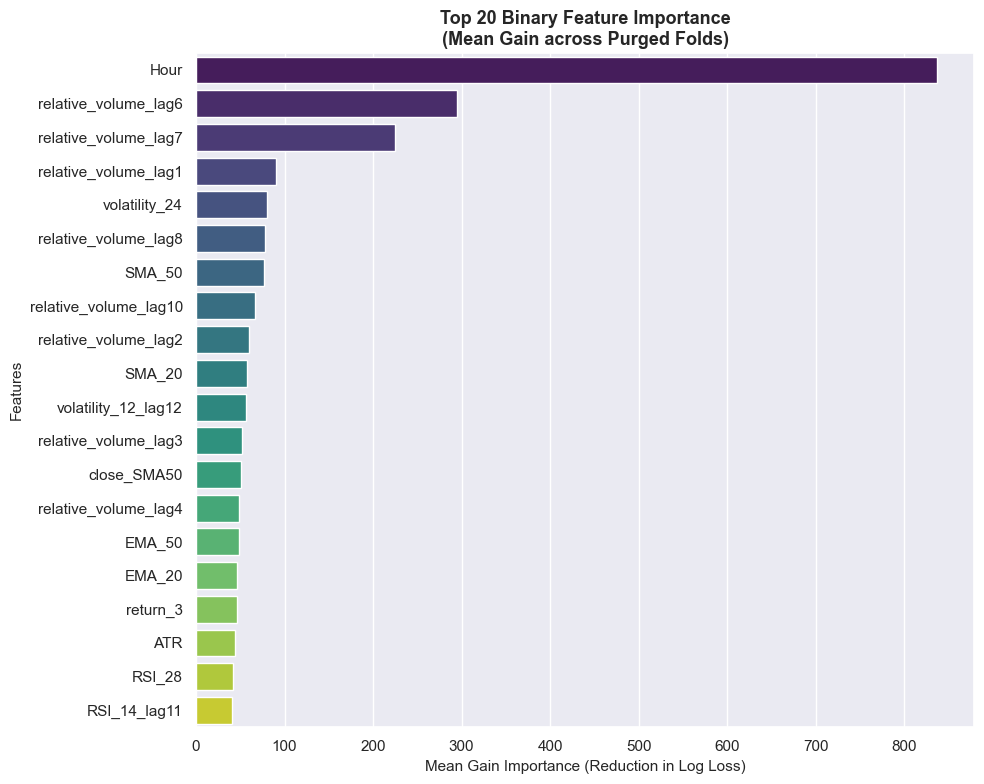

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMClassifier

def get_cv_binary_feature_importances(X_features, y_binary, cv_splitter, sample_weights, best_params):
    """
    Trains models across purged cross-validation folds and aggregates 
    feature importances (Gain-based) for binary classification.
    """
    feature_names = X_features.columns
    importance_df = pd.DataFrame(index=feature_names)
    
    fit_params = best_params.copy()
    fit_params['objective'] = 'binary'
    if 'num_class' in fit_params: del fit_params['num_class']
    fit_params['verbose'] = -1
    
    for fold, (train_idx, test_idx) in enumerate(cv_splitter.split(X_features)):
        X_train = X_features.iloc[train_idx]
        y_train = y_binary.iloc[train_idx]
        w_train = sample_weights[train_idx]
        
        # Train binary model
        model = LGBMClassifier(**fit_params)
        model.fit(X_train, y_train, sample_weight=w_train)
        
        importance_df[f'fold_{fold+1}'] = model.booster_.feature_importance(importance_type='gain')
        
    importance_df['mean_importance'] = importance_df.mean(axis=1)
    importance_df = importance_df.sort_values(by='mean_importance', ascending=False)
    
    return importance_df


sample_weights = compute_sample_weights(t1_series, X_features.index)
y_binary_labels_for_plot = (y_labels == 1).astype(int)

binary_cv_importances = get_cv_binary_feature_importances(
    X_features, 
    y_binary_labels_for_plot, 
    cv, 
    sample_weights, 
    study.best_params 
)

%matplotlib inline
plt.figure(figsize=(10, 8))
top_20_features = binary_cv_importances.head(20)

ax = sns.barplot(
    data=top_20_features,
    x='mean_importance',
    y=top_20_features.index,
    hue=top_20_features.index,
    palette='viridis',
    legend=False
)

plt.title('Top 20 Binary Feature Importance\n(Mean Gain across Purged Folds)', fontsize=13, fontweight='bold')
plt.xlabel('Mean Gain Importance (Reduction in Log Loss)', fontsize=11)
plt.ylabel('Features', fontsize=11)
plt.tight_layout()

plt.show()

=== Out-of-Fold (OOF) Evaluation Report ===
              precision    recall  f1-score   support

           0       0.73      0.98      0.83      8295
           1       0.45      0.05      0.09      3170

    accuracy                           0.72     11465
   macro avg       0.59      0.51      0.46     11465
weighted avg       0.65      0.72      0.63     11465

Out-of-Fold ROC-AUC: 0.6785


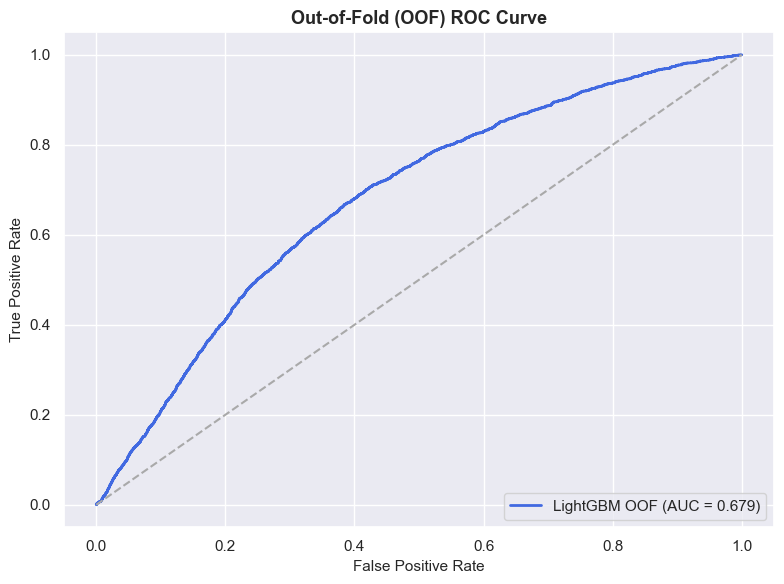

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

# 1. Prepare target and container using your best parameters
y_binary = (y_labels == 1).astype(int)
oof_probs = np.zeros(len(X_features))

best_params = study.best_params.copy()
best_params['objective'] = 'binary'
best_params['random_state'] = 42
best_params['n_jobs'] = -1
best_params['verbose'] = -1

# 2. Run a single CV loop to harvest OOF probabilities
for train_idx, test_idx in cv.split(X_features):
    X_train, X_test = X_features.iloc[train_idx], X_features.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    w_train = sample_weights[train_idx]
    
    model = LGBMClassifier(**best_params)
    model.fit(X_train, y_train, sample_weight=w_train)
    oof_probs[test_idx] = model.predict_proba(X_test)[:, 1]

# 3. Calculate and print metrics
oof_auc = roc_auc_score(y_binary, oof_probs)
y_pred_binary = (oof_probs >= 0.5).astype(int)

print("=== Out-of-Fold (OOF) Evaluation Report ===")
print(classification_report(y_binary, y_pred_binary))
print(f"Out-of-Fold ROC-AUC: {oof_auc:.4f}")

# 4. Plot ROC Curve
fpr, tpr, _ = roc_curve(y_binary, oof_probs)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='royalblue', label=f'LightGBM OOF (AUC = {oof_auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--')
plt.title('Out-of-Fold (OOF) ROC Curve', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [65]:
import backtrader as bt
import pandas as pd
import numpy as np

# 1. Ensure your dataframe has the required columns ready
df_bt = df_processed.copy()
df_bt['prob_success'] = oof_probs

# Re-apply filters & probability threshold
primary_longs = (
    (df_bt['Close'] > df_bt['Close'].ewm(span=50).mean()) & 
    (df_bt['ATR'] > df_bt['ATR'].rolling(20).mean())
)
threshold = pd.Series(oof_probs).quantile(0.80)
df_bt['signal'] = (primary_longs & (df_bt['prob_success'] >= threshold)).astype(int)

# 2. Custom Data Feed supporting ATR and signals
class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

# 3. Strategy with your chosen multipliers and active logging
class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', True),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def log(self, txt, dt=None):
        if self.params.printlog:
            dt = dt or self.datas[0].datetime.date(0)
            print(f'{dt.isoformat()} {txt}')

    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return

        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED (Entry), Price: {order.executed.price:.2f}')
            else:
                self.log(f'SELL EXECUTED (TP/SL Exit), Price: {order.executed.price:.2f}')

        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_distance = current_atr * self.params.tp_mult
                sl_distance = current_atr * self.params.sl_mult
                
                tp_price = entry_price + tp_distance
                sl_price = entry_price - sl_distance

                self.log(f'SIGNAL: Long at {entry_price:.2f} | ATR: {current_atr:.2f} | TP: {tp_price:.2f} | SL: {sl_price:.2f}')

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

# 4. Initialize Cerebro and Execute
cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
print(f'Final Portfolio Value:   ${cerebro.broker.getvalue():,.2f}')


Starting Portfolio Value: $10,000.00
2024-10-22 SIGNAL: Long at 20460.50 | ATR: 51.49 | TP: 20589.22 | SL: 20409.01
2024-10-22 BUY EXECUTED (Entry), Price: 20461.25
2024-10-22 SELL EXECUTED (TP/SL Exit), Price: 20589.22
2024-10-28 SIGNAL: Long at 20556.25 | ATR: 58.87 | TP: 20703.42 | SL: 20497.38
2024-10-28 BUY EXECUTED (Entry), Price: 20555.75
2024-10-28 SELL EXECUTED (TP/SL Exit), Price: 20497.38
2024-11-12 SIGNAL: Long at 21235.00 | ATR: 43.92 | TP: 21344.79 | SL: 21191.08
2024-11-12 BUY EXECUTED (Entry), Price: 21234.50
2024-11-12 SELL EXECUTED (TP/SL Exit), Price: 21184.00
2024-12-06 SIGNAL: Long at 21608.00 | ATR: 37.77 | TP: 21702.43 | SL: 21570.23
2024-12-06 BUY EXECUTED (Entry), Price: 21607.25
2024-12-09 SELL EXECUTED (TP/SL Exit), Price: 21702.43
2024-12-17 SIGNAL: Long at 22106.75 | ATR: 79.41 | TP: 22305.28 | SL: 22027.34
2024-12-17 BUY EXECUTED (Entry), Price: 22107.25
2024-12-17 SELL EXECUTED (TP/SL Exit), Price: 22305.28
2025-01-15 SIGNAL: Long at 21281.25 | ATR: 79.45

<h1>Removing Hour Column<h1>

In [62]:
import optuna
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier

if 'Hour' in X_features.columns:
    X_features_no_hr = X_features.drop(columns=['Hour'])
    print("Dropped 'Hour' from X_features.")

optuna.logging.set_verbosity(optuna.logging.WARNING)
sample_weights = compute_sample_weights(t1_series, X_features.index)

def objective_no_hour(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'num_leaves': trial.suggest_int('num_leaves', 4, 32),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }
    
    y_binary = (y_labels == 1).astype(int)
    fold_log_losses = []

    for train_idx, test_idx in cv.split(X_features_no_hr):
        X_train, X_test = X_features_no_hr.iloc[train_idx], X_features_no_hr.iloc[test_idx]
        y_train, y_test = y_binary.iloc[train_idx], y_binary.iloc[test_idx]
        
        w_train = sample_weights[train_idx]
        
        model_no_hr = LGBMClassifier(**params)
        model_no_hr.fit(X_train, y_train, sample_weight=w_train)
        
        preds_proba = model_no_hr.predict_proba(X_test)[:, 1]
        loss = log_loss(y_test, preds_proba)
        fold_log_losses.append(loss)
        
    return np.mean(fold_log_losses)

print("Starting Multi-Class Optuna Hyperparameter Search (No Hour Model)...")
study_no_hr = optuna.create_study(direction='minimize')
study_no_hr.optimize(objective_no_hour, n_trials=30, show_progress_bar=True)

print("\n--- Best Binary-Class Hyperparameters Found ---")
for key, value in study_no_hr.best_params.items():
    print(f"  {key}: {value}")
print(f"Best Mean Binary-Class Log Loss: {study_no_hr.best_value:.4f}")

Dropped 'Hour' from X_features.
Starting Multi-Class Optuna Hyperparameter Search (No Hour Model)...


  0%|          | 0/30 [00:00<?, ?it/s]


--- Best Binary-Class Hyperparameters Found ---
  n_estimators: 188
  learning_rate: 0.01717381473719015
  max_depth: 6
  num_leaves: 22
  subsample: 0.8175753611197547
  colsample_bytree: 0.6450526984179183
  min_child_samples: 62
  reg_alpha: 0.0013409462957808948
  reg_lambda: 0.11530505488582643
Best Mean Binary-Class Log Loss: 0.5523


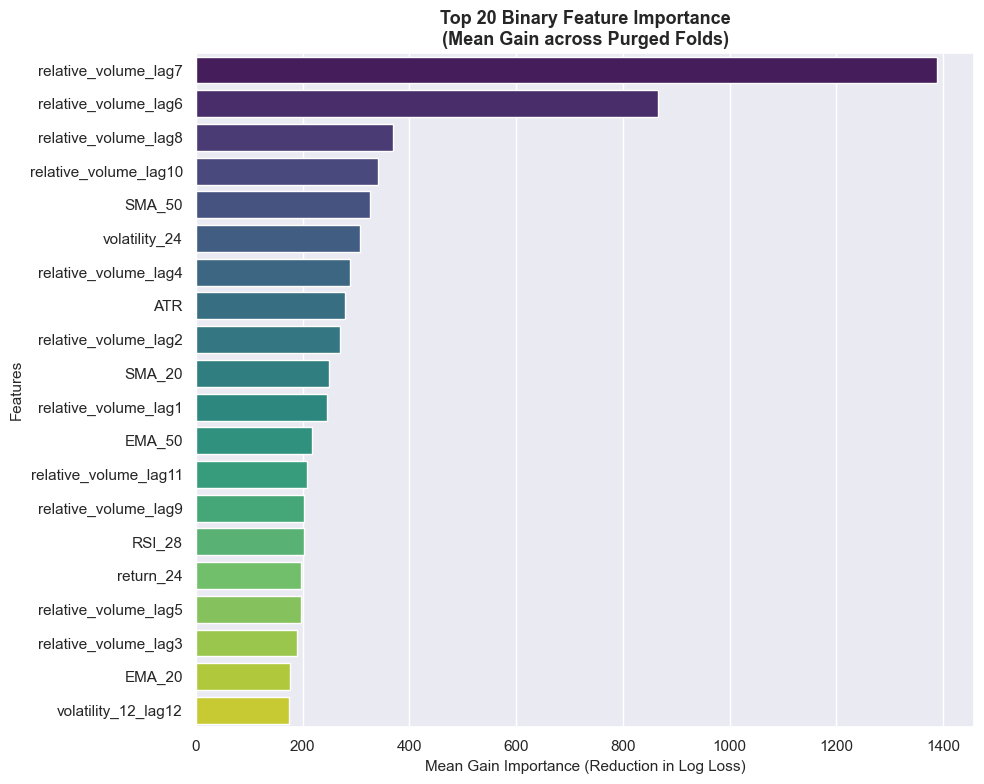

In [63]:
binary_cv_importances = get_cv_binary_feature_importances(
    X_features_no_hr, 
    y_binary_labels_for_plot, 
    cv, 
    sample_weights, 
    study_no_hr.best_params 
)

%matplotlib inline
plt.figure(figsize=(10, 8))
top_20_features = binary_cv_importances.head(20)

ax = sns.barplot(
    data=top_20_features,
    x='mean_importance',
    y=top_20_features.index,
    hue=top_20_features.index,
    palette='viridis',
    legend=False
)

plt.title('Top 20 Binary Feature Importance\n(Mean Gain across Purged Folds)', fontsize=13, fontweight='bold')
plt.xlabel('Mean Gain Importance (Reduction in Log Loss)', fontsize=11)
plt.ylabel('Features', fontsize=11)
plt.tight_layout()

plt.show()

=== Out-of-Fold (OOF) Evaluation Report ===
              precision    recall  f1-score   support

           0       0.73      0.97      0.83      8295
           1       0.40      0.06      0.11      3170

    accuracy                           0.72     11465
   macro avg       0.57      0.51      0.47     11465
weighted avg       0.64      0.72      0.63     11465

Out-of-Fold ROC-AUC: 0.6734


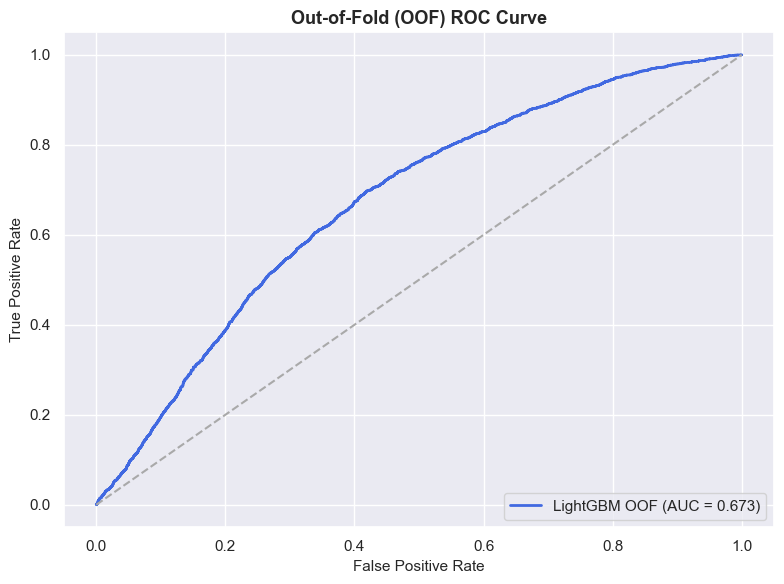

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

# 1. Prepare target and container using your best parameters
y_binary = (y_labels == 1).astype(int)
oof_probs_no_hr = np.zeros(len(X_features_no_hr))

best_params_no_hr = study_no_hr.best_params.copy()
best_params_no_hr['objective'] = 'binary'
best_params_no_hr['random_state'] = 42
best_params_no_hr['n_jobs'] = -1
best_params_no_hr['verbose'] = -1
for train_idx, test_idx in cv.split(X_features_no_hr):
    X_train, X_test = X_features_no_hr.iloc[train_idx], X_features_no_hr.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    w_train = sample_weights[train_idx]
    
    model_no_hr = LGBMClassifier(**best_params_no_hr)
    model_no_hr.fit(X_train, y_train, sample_weight=w_train)
    oof_probs_no_hr[test_idx] = model_no_hr.predict_proba(X_test)[:, 1]

# 3. Calculate and print metrics
oof_auc_no_hr = roc_auc_score(y_binary, oof_probs_no_hr)
y_pred_binary_no_hr = (oof_probs_no_hr >= 0.5).astype(int)

print("=== Out-of-Fold (OOF) Evaluation Report ===")
print(classification_report(y_binary, y_pred_binary_no_hr))
print(f"Out-of-Fold ROC-AUC: {oof_auc_no_hr:.4f}")

# 4. Plot ROC Curve
fpr, tpr, _ = roc_curve(y_binary, oof_probs_no_hr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='royalblue', label=f'LightGBM OOF (AUC = {oof_auc_no_hr:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--')
plt.title('Out-of-Fold (OOF) ROC Curve', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
import backtrader as bt
import pandas as pd
import numpy as np

# 1. Ensure your dataframe has the required columns ready
df_bt = df_processed.copy()
df_bt['prob_success'] = oof_probs

# Re-apply filters & probability threshold
primary_longs = (
    (df_bt['Close'] > df_bt['Close'].ewm(span=50).mean()) & 
    (df_bt['ATR'] > df_bt['ATR'].rolling(20).mean())
)
threshold = pd.Series(oof_probs).quantile(0.80)
df_bt['signal'] = (primary_longs & (df_bt['prob_success'] >= threshold)).astype(int)

# 2. Custom Data Feed supporting ATR and signals
class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

# 3. Strategy with your chosen multipliers and active logging
class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', True),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def log(self, txt, dt=None):
        if self.params.printlog:
            dt = dt or self.datas[0].datetime.date(0)
            print(f'{dt.isoformat()} {txt}')

    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return

        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED (Entry), Price: {order.executed.price:.2f}')
            else:
                self.log(f'SELL EXECUTED (TP/SL Exit), Price: {order.executed.price:.2f}')

        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_distance = current_atr * self.params.tp_mult
                sl_distance = current_atr * self.params.sl_mult
                
                tp_price = entry_price + tp_distance
                sl_price = entry_price - sl_distance

                self.log(f'SIGNAL: Long at {entry_price:.2f} | ATR: {current_atr:.2f} | TP: {tp_price:.2f} | SL: {sl_price:.2f}')

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

# 4. Initialize Cerebro and Execute
cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
print(f'Final Portfolio Value:   ${cerebro.broker.getvalue():,.2f}')


In [66]:
import backtrader as bt
import pandas as pd
import numpy as np

# 1. Prepare dataframe with No-Hour OOF probabilities
df_bt = df_processed.copy()
df_bt['prob_success'] = oof_probs_no_hr

# Re-apply primary trend filters and top 20% probability threshold
primary_longs = (
    (df_bt['Close'] > df_bt['Close'].ewm(span=50).mean()) & 
    (df_bt['ATR'] > df_bt['ATR'].rolling(20).mean())
)
threshold = pd.Series(oof_probs_no_hr).quantile(0.80)
df_bt['signal'] = (primary_longs & (df_bt['prob_success'] >= threshold)).astype(int)

# 2. Custom Data Feed supporting ATR and signals
class MLATRData(bt.feeds.PandasData):
    lines = ('prob_success', 'signal', 'ATR')
    params = (
        ('prob_success', 'prob_success'),
        ('signal', 'signal'),
        ('ATR', 'ATR'),
    )

# 3. Strategy with 2.5x ATR TP, 1.0x ATR SL, and active logging
class DynamicATRBarrierStrategy(bt.Strategy):
    params = (
        ('tp_mult', 2.5),  # 2.5x ATR Take Profit
        ('sl_mult', 1.0),  # 1.0x ATR Stop Loss
        ('printlog', True),
    )

    def __init__(self):
        self.dataclose = self.datas[0].close
        self.prob_success = self.datas[0].prob_success
        self.signal = self.datas[0].signal
        self.atr = self.datas[0].ATR
        self.orefs = []

    def log(self, txt, dt=None):
        if self.params.printlog:
            dt = dt or self.datas[0].datetime.date(0)
            print(f'{dt.isoformat()} {txt}')

    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return

        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f'BUY EXECUTED (Entry), Price: {order.executed.price:.2f}')
            else:
                self.log(f'SELL EXECUTED (TP/SL Exit), Price: {order.executed.price:.2f}')

        if order.status in [order.Completed, order.Canceled, order.Margin, order.Rejected]:
            self.orefs = [ref for ref in self.orefs if ref != order.ref]

    def next(self):
        if self.orefs:
            return

        if not self.position:
            if self.signal[0] == 1:
                entry_price = self.dataclose[0]
                current_atr = self.atr[0]
                
                tp_distance = current_atr * self.params.tp_mult
                sl_distance = current_atr * self.params.sl_mult
                
                tp_price = entry_price + tp_distance
                sl_price = entry_price - sl_distance

                self.log(f'SIGNAL: Long at {entry_price:.2f} | ATR: {current_atr:.2f} | TP: {tp_price:.2f} | SL: {sl_price:.2f}')

                bracket = self.buy_bracket(
                    size=1,
                    price=entry_price,
                    exectype=bt.Order.Market,
                    stopprice=sl_price,
                    limitprice=tp_price
                )
                self.orefs = [o.ref for o in bracket]

# 4. Initialize Cerebro and Execute
cerebro = bt.Cerebro()
cerebro.addstrategy(DynamicATRBarrierStrategy)

data = MLATRData(
    dataname=df_bt,
    datetime=None,
    open='Open', high='High', low='Low', close='Close', volume='Volume'
)
cerebro.adddata(data)

cerebro.broker.setcash(10000.0)
cerebro.broker.setcommission(commission=0.62, margin=500.0, mult=2.0)

print(f'Starting Portfolio Value: ${cerebro.broker.getvalue():,.2f}')
cerebro.run()
final_val = cerebro.broker.getvalue()
print(f'Final Portfolio Value (No-Hour Model): ${final_val:,.2f}')
print(f'Net Strategy Return:                   ${final_val - 10000.0:,.2f}')


Starting Portfolio Value: $10,000.00
2024-10-22 SIGNAL: Long at 20460.50 | ATR: 51.49 | TP: 20589.22 | SL: 20409.01
2024-10-22 BUY EXECUTED (Entry), Price: 20461.25
2024-10-22 SELL EXECUTED (TP/SL Exit), Price: 20589.22
2024-10-28 SIGNAL: Long at 20556.25 | ATR: 58.87 | TP: 20703.42 | SL: 20497.38
2024-10-28 BUY EXECUTED (Entry), Price: 20555.75
2024-10-28 SELL EXECUTED (TP/SL Exit), Price: 20497.38
2024-11-06 SIGNAL: Long at 20728.50 | ATR: 74.75 | TP: 20915.36 | SL: 20653.75
2024-11-06 BUY EXECUTED (Entry), Price: 20728.00
2024-11-06 SELL EXECUTED (TP/SL Exit), Price: 20653.75
2024-12-03 SIGNAL: Long at 21207.00 | ATR: 34.93 | TP: 21294.32 | SL: 21172.07
2024-12-03 BUY EXECUTED (Entry), Price: 21207.50
2024-12-03 SELL EXECUTED (TP/SL Exit), Price: 21294.32
2024-12-04 SIGNAL: Long at 21482.75 | ATR: 37.90 | TP: 21577.50 | SL: 21444.85
2024-12-04 BUY EXECUTED (Entry), Price: 21482.75
2024-12-04 SELL EXECUTED (TP/SL Exit), Price: 21444.85
2024-12-04 SIGNAL: Long at 21471.50 | ATR: 39.65

In [67]:
import pandas_ta as ta
import pandas as pd

def compute_live_features(mnq_hr, target_col='Close', lags=12):
    """
    Computes all technical indicators, momentum metrics, and lags 
    for live inference using your exact historical feature logic, 
    safely omitting the future-looking Triple Barrier labels.
    """
    df_ml = mnq_hr.copy()
    if 'Hour' in df_ml.columns:
        df_ml = df_ml.drop(columns=['Hour'])

    for period in [1, 3, 6, 12, 24]:
        df_ml[f'return_{period}'] = df_ml[target_col].pct_change(period)
    df_ml['SMA_20'] = ta.sma(df_ml[target_col], length=20)
    df_ml['SMA_50'] = ta.sma(df_ml[target_col], length=50)
    df_ml['EMA_20'] = ta.ema(df_ml[target_col], length=20)
    df_ml['EMA_50'] = ta.ema(df_ml[target_col], length=50)

    df_ml['close_SMA20'] = df_ml[target_col] / df_ml['SMA_20'] - 1
    df_ml['close_SMA50'] = df_ml[target_col] / df_ml['SMA_50'] - 1
    df_ml['close_EMA20'] = df_ml[target_col] / df_ml['EMA_20'] - 1
    df_ml['close_EMA50'] = df_ml[target_col] / df_ml['EMA_50'] - 1

    df_ml['RSI_7'] = ta.rsi(df_ml[target_col], length=7)
    df_ml['RSI_14'] = ta.rsi(df_ml[target_col], length=14)
    df_ml['RSI_28'] = ta.rsi(df_ml[target_col], length=28)

    df_ml['ATR'] = ta.atr(df_ml['High'], df_ml['Low'], df_ml['Close'], length=14)
    df_ml['volatility_regime'] = (df_ml['ATR'] > df_ml['ATR'].rolling(50).mean()).astype(int)

    macd = ta.macd(df_ml[target_col])
    df_ml['MACD'] = macd['MACD_12_26_9']
    df_ml['MACD_signal'] = macd['MACDs_12_26_9']
    df_ml['MACD_hist'] = macd['MACDh_12_26_9']

    df_ml['volatility_6'] = df_ml['return_1'].rolling(6).std()
    df_ml['volatility_12'] = df_ml['return_1'].rolling(12).std()
    df_ml['volatility_24'] = df_ml['return_1'].rolling(24).std()

    df_ml['range'] = (df_ml['High'] - df_ml['Low']) / df_ml[target_col]
    df_ml['open_close'] = (df_ml['Close'] - df_ml['Open']) / df_ml['Open']
    df_ml['relative_volume'] = df_ml['Volume'] / df_ml['Volume'].rolling(20).mean()

    lag_columns = ['return_1', 'return_3', 'RSI_14', 'MACD_hist', 'volatility_12', 'relative_volume']
    lag_features = {}
    for col in lag_columns:
        for lag in range(1, lags + 1):
            lag_features[f'{col}_lag{lag}'] = df_ml[col].shift(lag)

    df_ml = pd.concat([df_ml, pd.DataFrame(lag_features, index=df_ml.index)], axis=1)
    
    df_ml = df_ml.dropna(subset=['ATR', 'EMA_50', 'relative_volume'])
    
    return df_ml



In [ ]:
from lightgbm import LGBMClassifier

best_params = profit_study_no_hour.best_params
best_params.update({
    'random_state': 42, 
    'n_jobs': -1, 
    'verbose': -1, 
    'objective': 'binary'
})

y_binary = (y_labels == 1).astype(int)


best_model = LGBMClassifier(**best_params)
best_model.fit(X_features, y_binary, sample_weight=sample_weights)

print("best_model is now successfully trained, defined, and ready for live prediction!")

best_model is now successfully trained, defined, and ready for live prediction!


In [ ]:
from sklearn.model_selection import KFold

cv = KFold(n_splits=5, shuffle=False)
oof_probs = np.zeros(len(X_features))
y_binary = (y_labels == 1).astype(int)

for train_idx, test_idx in cv.split(X_features):
    X_tr, X_te = X_features.iloc[train_idx], X_features.iloc[test_idx]
    y_tr = y_binary.iloc[train_idx]
    w_tr = sample_weights[train_idx]
    
    temp_model = LGBMClassifier(**best_params)
    temp_model.fit(X_tr, y_tr, sample_weight=w_tr)
    oof_probs[test_idx] = temp_model.predict_proba(X_te)[:, 1]

optimal_threshold = pd.Series(oof_probs).quantile(0.80)

print(f"optimal_threshold is now set to: {optimal_threshold:.4f}")

optimal_threshold is now set to: 0.4337


In [2]:
import numpy as np
import pandas as pd

y_binary = (y_labels == 1).astype(int)

trade_outcomes = np.zeros(len(oof_probs))
trade_outcomes[y_labels == 1] = 2.5
trade_outcomes[y_labels == -1] = -1.0


temp_df = df_processed.copy()
primary_longs = (
    (temp_df['Close'] > temp_df['Close'].ewm(span=50).mean()) & 
    (temp_df['ATR'] > temp_df['ATR'].rolling(20).mean())
)

results = []
percentiles = range(50, 96, 2)

for p in percentiles:
    thresh = pd.Series(oof_probs).quantile(p / 100.0)
    selected = primary_longs & (oof_probs >= thresh)
    
    if selected.sum() < 10: 
        continue
        
    filtered_pnl = trade_outcomes[selected]
    gross_profits = filtered_pnl[filtered_pnl > 0].sum()
    gross_losses = abs(filtered_pnl[filtered_pnl < 0].sum())
    
    pf = gross_profits / gross_losses if gross_losses > 0 else float(len(filtered_pnl))
    win_len = len(filtered_pnl[filtered_pnl > 0])
    win_rate = (win_len / len(filtered_pnl)) * 100 if len(filtered_pnl) > 0 else 0
    
    results.append({
        'percentile': p,
        'threshold': thresh,
        'trades': len(filtered_pnl),
        'win_rate': win_rate,
        'profit_factor': pf
    })

results_df = pd.DataFrame(results)
best_row = results_df.loc[results_df['profit_factor'].idxmax()]

print("=== THRESHOLD SWEEP RESULTS ===")
print(results_df.sort_values(by='profit_factor', ascending=False).head(5))
print("\nTRUE OPTIMAL:")
print(f"Best Percentile : {best_row['percentile']}th (Threshold: {best_row['threshold']:.4f})")
print(f"Resulting PF    : {best_row['profit_factor']:.2f}")
print(f"Win Rate        : {best_row['win_rate']:.1f}%")
print(f"Total Trades    : {int(best_row['trades'])}")

optimal_threshold = best_row['threshold']

NameError: name 'y_labels' is not defined

In [ ]:
import pandas as pd
import numpy as np

print("Fetching latest market data via yfinance...")
mnq_hr_updated = mnq_hr

print(f"Latest available bar in updated data: {mnq_hr_updated.index[-1]}")
print(f"Latest close price: {mnq_hr_updated['Close'].iloc[-1]:.2f}")

df_live_features = compute_live_features(mnq_hr_updated)

live_features = df_live_features.iloc[-1].copy()
X_input = pd.DataFrame([live_features])[X_features.columns]
probs = best_model.predict_proba(X_input)[0]
prob_no_success = probs[0]
prob_success = probs[1]

current_close = mnq_hr_updated['Close'].iloc[-1]
current_atr = live_features['ATR']
ema_50 = live_features['EMA_50']
atr_rolling_mean = df_live_features['ATR'].rolling(20).mean().iloc[-1]

trend_ok = current_close > ema_50
vol_ok = current_atr > atr_rolling_mean

print("\n" + "="*45)
print("          LIVE INFERENCE PROBABILITY REPORT         ")
print("="*45)
print(f"Timestamp Evaluated   : {mnq_hr_updated.index[-1]}")
print(f"P(No Success / Flat)  : {prob_no_success * 100:.2f}% ({prob_no_success:.4f})")
print(f"P(Success / Long)     : {prob_success * 100:.2f}% ({prob_success:.4f})")
print(f"Decision Threshold    : {optimal_threshold * 100:.2f}% ({optimal_threshold:.4f})")
print("-" * 45)
print(f"Trend Gate (Cl > EMA50): {trend_ok} ({current_close:.2f} vs {ema_50:.2f})")
print(f"Vol Gate (ATR > Mean) : {vol_ok} ({current_atr:.2f} vs {atr_rolling_mean:.2f})")
print("-" * 45)

if trend_ok and vol_ok and (prob_success >= optimal_threshold):
    tp_target = current_close + (2.5 * current_atr)
    sl_target = current_close - (1.0 * current_atr)
    print(f" SIGNAL TRIGGERED: GO LONG")
    print(f" Take Profit Target : {tp_target:.2f}")
    print(f" Stop Loss Target   : {sl_target:.2f}")
else:
    print("SIGNAL: STAND FLAT (Criteria not met)")
print("="*45)

Fetching latest market data via yfinance...
Latest available bar in updated data: 2026-10-12 13:00:00
Latest close price: 30892.50

          LIVE INFERENCE PROBABILITY REPORT         
Timestamp Evaluated   : 2026-10-12 13:00:00
P(No Success / Flat)  : 76.35% (0.7635)
P(Success / Long)     : 23.65% (0.2365)
Decision Threshold    : 36.54% (0.3654)
---------------------------------------------
Trend Gate (Cl > EMA50): False (30892.50 vs 31121.42)
Vol Gate (ATR > Mean) : True (78.21 vs 77.00)
---------------------------------------------
SIGNAL: STAND FLAT (Criteria not met)


In [ ]:
temp_df = df_processed.copy()
primary_longs = (
    (temp_df['Close'] > temp_df['Close'].ewm(span=50).mean()) & 
    (temp_df['ATR'] > temp_df['ATR'].rolling(20).mean())
)
selected_signals = primary_longs & (oof_probs >= optimal_threshold)

if 't1' in df_processed.columns:
    entry_indices = np.where(selected_signals)[0]
    exit_indices = df_processed['t1'].iloc[entry_indices].values
    
    valid_mask = ~pd.isna(exit_indices)
    
    if valid_mask.sum() > 0:
        if pd.api.types.is_datetime64_any_dtype(df_processed['t1']):
            durations = (pd.to_datetime(df_processed['t1'].iloc[entry_indices[valid_mask]]) - 
                         pd.to_datetime(df_processed.index[entry_indices[valid_mask]])).dt.total_seconds() / 3600.0
        else:
            durations = exit_indices[valid_mask] - entry_indices[valid_mask]
            
        print(f"Total Selected Trades   : {valid_mask.sum()}")
        print(f"Empirical Average Hold  : ~{np.mean(durations):.1f} hours")
        print(f"Median Holding Time     : ~{np.median(durations):.1f} hours")
    else:
        print("No valid trade exits found in 't1'.")
else:
    print("'t1' column not found in df_processed.")

Total Selected Trades   : 375
Empirical Average Hold  : ~6.0 hours
Median Holding Time     : ~3.0 hours


In [ ]:
selected_indices = np.where(selected_signals)[0]
filtered_labels = y_labels.iloc[selected_indices]

wins = (filtered_labels == 1).sum()
losses = (filtered_labels == -1).sum()
neutrals = (filtered_labels == 0).sum()
total_trades = len(filtered_labels)

win_rate = (wins / (wins + losses)) * 100 if (wins + losses) > 0 else 0

print("="*40)
print("     FILTERED SIGNAL PERFORMANCE BREAKDOWN     ")
print("="*40)
print(f"Total Selected Signals : {total_trades}")
print(f"Winning Trades (+1)    : {wins} ({wins/total_trades*100:.1f}%)")
print(f"Losing Trades (-1)     : {losses} ({losses/total_trades*100:.1f}%)")
print(f"Neutral / Timeout (0)  : {neutrals} ({neutrals/total_trades*100:.1f}%)")
print("-" * 40)
print(f"Win Rate (Win / Loss)  : {win_rate:.1f}%")

net_expectancy = (wins * 2.5) - (losses * 1.0)
avg_expectancy_per_trade = net_expectancy / total_trades if total_trades > 0 else 0
print(f"Expectancy (in ATR units): {avg_expectancy_per_trade:+.3f} ATR per trade")
print("="*40)

     FILTERED SIGNAL PERFORMANCE BREAKDOWN     
Total Selected Signals : 375
Winning Trades (+1)    : 142 (37.9%)
Losing Trades (-1)     : 136 (36.3%)
Neutral / Timeout (0)  : 97 (25.9%)
----------------------------------------
Win Rate (Win / Loss)  : 51.1%
Expectancy (in ATR units): +0.584 ATR per trade


In [30]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp

def check_feature_drift(baseline_path="training_features_baseline.parquet", 
                        live_path="live_features_audit.csv", 
                        p_threshold=0.01):
    
    print("🔍 Loading baseline and live feature logs...")
    df_train = pd.read_parquet(baseline_path)
    df_live = pd.read_csv(live_path)
    
    # Exclude non-feature columns if present in live log
    exclude_cols = ['timestamp', 'prob_success', 'signal_triggered']
    feature_cols = [c for c in df_train.columns if c in df_live.columns and c not in exclude_cols]
    
    drift_results = []
    
    print(f"\nRunning K-S Test across {len(feature_cols)} features...")
    print("-" * 65)
    print(f"{'Feature Name':<25} | {'KS Statistic':<12} | {'P-Value':<10} | {'Status'}")
    print("-" * 65)
    
    for col in feature_cols:
        train_data = df_train[col].dropna()
        live_data = df_live[col].dropna()
        
        if len(live_data) < 10:
            # Skip if not enough live samples yet
            continue
            
        # Perform two-sample Kolmogorov-Smirnov test
        ks_stat, p_val = ks_2samp(train_data, live_data)
        
        is_drifted = p_val < p_threshold
        status = "🚨 DRIFT DETECTED" if is_drifted else "✅ Stable"
        
        if is_drifted:
            drift_results.append(col)
            
        print(f"{col:<25} | {ks_stat:<12.4f} | {p_val:<10.4e} | {status}")
        
    print("-" * 65)
    if drift_results:
        print(f"\n⚠️ WARNING: {len(drift_results)} feature(s) showed significant drift: {drift_results}")
        print("Consider retraining your model or adjusting features for the new market regime.")
    else:
        print("\n✨ All features are stable! No statistically significant drift detected.")

# Execute drift check
check_feature_drift()

🔍 Loading baseline and live feature logs...


FileNotFoundError: [Errno 2] No such file or directory: 'live_features_audit.csv'